Reviews loaded: 20000
Date range: 2026-08-26 to 2026-10-21
Negative reviews: 1947 of 20000

=== Share of NEGATIVE reviews mentioning each theme ===
cancellation: 33.7%
refund / money: 27.5%
support: 21.8%
trust / fraud: 12.6%
late / delay: 10.5%
no-show / unavailable: 7.6%
pricing: 3.6%
quality: 3.4%
app bug: 2.0%

=== Theme share by month (negative reviews only) ===


,cancellation,no-show / unavailable,refund / money,support,late / delay,quality,pricing,trust / fraud,app bug
month,,,,,,,,,
2026-08,0.34,0.07,0.25,0.26,0.14,0.01,0.03,0.14,0.01
2026-09,0.32,0.08,0.25,0.22,0.09,0.04,0.05,0.12,0.02
2026-10,0.36,0.08,0.32,0.20,0.11,0.03,0.02,0.13,0.03


=== Overall share of negative reviews by month ===


month
2026-08    0.11
2026-09    0.09
2026-10    0.11
Freq: M, Name: negative, dtype: float64


=== Among negative reviews that mention cancellation ===
Count: 656
Also mention refund/money: 41.3%
Also mention support: 24.5%

=== 10 random cancellation reviews ===
- unreliable. for bookings made 2 days in advance pronto cancelled at the last minute. twice. 

- horrible experience, they cancelled without my consent and confirmation. they get 30-40 minutes late but if we take 5 minutes extra to respond they cancel without asking and no refund. such hypocrisy and unprofessionalism. 

- the house help never comes on time. if you schedule your booking for 3:30 pm till 5pm they wont come. also they wont allow us to cancel the booking. they charge a complete booking amount for cancellation. worst service provider.they dont value customer's time. 

- worst fraudsers showing cheap prices third class app booking is rescheduled automatically with no chat and customer care support no one turned up cheating customers by looting money online.later service cancelled automatically,this mostly d

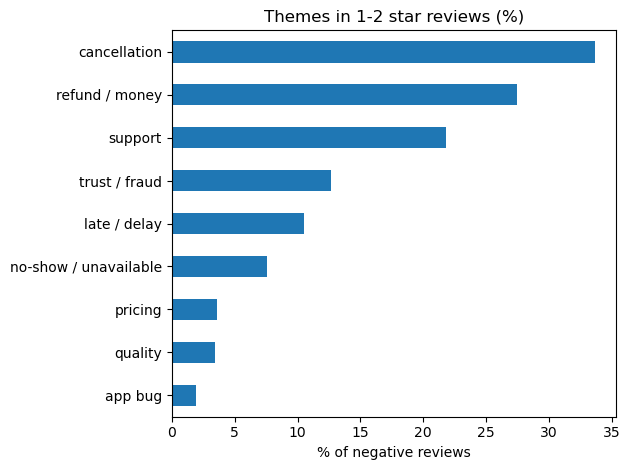

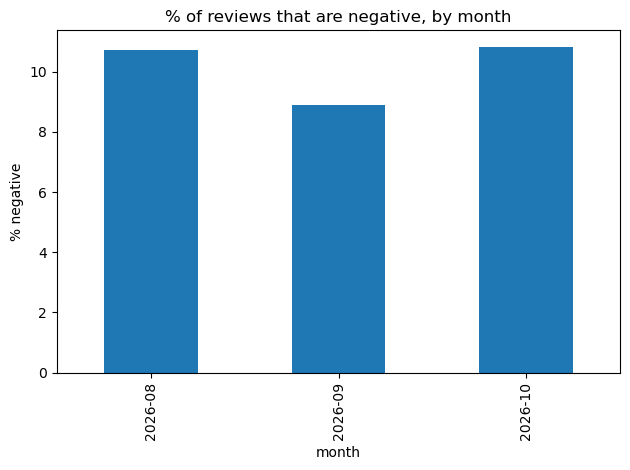

In [11]:
# --- Run this once if packages are missing, then restart the kernel ---
# %pip install google-play-scraper pandas matplotlib

import os
import pandas as pd
import matplotlib.pyplot as plt
from google_play_scraper import reviews, Sort

# ---------- SETTINGS ----------
APP_ID = "com.company.pronto"   # the part after id= in the Play Store URL
CSV_FILE = "pronto_reviews.csv"
HOW_MANY = 20000                # how many of the newest reviews to fetch

# ---------- STEP 1: GET THE DATA ----------
if not os.path.exists(CSV_FILE):
    print("Downloading reviews... this can take a few minutes.")
    result, _ = reviews(APP_ID, lang="en", country="in", sort=Sort.NEWEST, count=HOW_MANY)
    # Keep only review text, star rating and date (no usernames)
    data = pd.DataFrame(result)[["content", "score", "at"]]
    data.to_csv(CSV_FILE, index=False)
    print("Saved", CSV_FILE)

df = pd.read_csv(CSV_FILE)
print("Reviews loaded:", len(df))

# ---------- STEP 2: CLEAN AND LABEL ----------
df["at"] = pd.to_datetime(df["at"])                   # text -> real dates
df["content"] = df["content"].fillna("").str.lower()  # lowercase so "Cancel" = "cancel"
df["month"] = df["at"].dt.to_period("M")              # e.g. 2026-10
df["negative"] = df["score"] <= 2                     # 1-2 stars = negative

print("Date range:", df["at"].min().date(), "to", df["at"].max().date())
print("Negative reviews:", df["negative"].sum(), "of", len(df))

# ---------- STEP 3: DEFINE THEMES ----------
# "|" means "or": a review has the theme if it contains any of these words
themes = {
    "cancellation":          r"cancel",
    "no-show / unavailable": r"no.?show|not available|unavailable|didn.?t come|did not come|never came|no one came|nobody",
    "refund / money":        r"refund|money|charged|deduct",
    "support":               r"support|customer care|no response|helpline",
    "late / delay":          r"\blate\b|delay|waiting",
    "quality":               r"quality|dirty|not clean|poor work",
    "pricing":               r"price|expensive|costly|charges|\bfee\b",
    "trust / fraud":         r"fraud|scam|cheat|fake|misleading",
    "app bug":               r"address|\bbug\b|crash|glitch|login|payment fail",
}

# For each theme, make a True/False column: does this review mention it?
for name, pattern in themes.items():
    df[name] = df["content"].str.contains(pattern, regex=True)

# ---------- STEP 4: RESULTS ----------
neg = df[df["negative"]]   # only the negative reviews

print("\n=== Share of NEGATIVE reviews mentioning each theme ===")
shares = neg[list(themes)].mean().sort_values(ascending=False) * 100
for name, value in shares.items():
    print(f"{name}: {value:.1f}%")

print("\n=== Theme share by month (negative reviews only) ===")
display(neg.groupby("month")[list(themes)].mean().round(2))

print("=== Overall share of negative reviews by month ===")
display(df.groupby("month")["negative"].mean().round(2))

# Cancellation overlap with refunds and support
canc = neg[neg["cancellation"]]
print("\n=== Among negative reviews that mention cancellation ===")
print("Count:", len(canc))
print("Also mention refund/money: %.1f%%" % (canc["refund / money"].mean() * 100))
print("Also mention support: %.1f%%" % (canc["support"].mean() * 100))

# Read real reviews yourself (this checks that your keywords work)
print("\n=== 10 random cancellation reviews ===")
for text in canc["content"].sample(min(10, len(canc)), random_state=1):
    print("-", text[:300], "\n")

# ---------- STEP 5: CHARTS ----------
shares.sort_values().plot(kind="barh", title="Themes in 1-2 star reviews (%)")
plt.xlabel("% of negative reviews")
plt.tight_layout()
plt.savefig("themes.png", dpi=150)
plt.show()

df.groupby("month")["negative"].mean().mul(100).plot(
    kind="bar", title="% of reviews that are negative, by month"
)
plt.ylabel("% negative")
plt.tight_layout()
plt.savefig("monthly_negative.png", dpi=150)
plt.show()